# Wine Quality Prediction - Machine Learning Project (Fall 2026)
**University of Lahore | BSCS | Course: Machine Learning**


**Dataset:** Wine Quality (red + white wine) - Kaggle, file https://www.kaggle.com/datasets/ruthgn/wine-quality-data-set-red-white-wine

**Task:** Classification - predict wine quality class (Low / Medium / High)

**Idea of the project:** Train each model **two times (Run 1 and Run 2)** and compare **training time** and **accuracy / F1 score**.

- **Run 1** = normal CPU run (1 core / 1 thread)
- **Run 2** = faster setting (all CPU cores, or GPU for XGBoost if Colab GPU is on)

> Tip: For GPU, go to `Runtime -> Change runtime type -> T4 GPU` before running all cells.

## Section 1: Import Libraries
**What it does:** loads the Python libraries we need.
- `pandas`, `numpy` : work with data
- `matplotlib`, `seaborn` : draw graphs
- `sklearn` : machine learning models and metrics
- `time` : measure training time

In [13]:
import os, time, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")      # hide unnecessary warnings
sns.set_style("whitegrid")             # nicer graph style
RANDOM_STATE = 42                      # fixed number so results are same every time
N_CORES = os.cpu_count()               # number of CPU cores available
print("Libraries loaded. CPU cores available:", N_CORES)

Libraries loaded. CPU cores available: 2


## Section 2: Load Data and Exploratory Data Analysis - EDA
**What it does:** loads the CSV file and shows what the data looks like (rows, columns, statistics, graphs).

If the file is not already in Colab, a small upload box will appear. Upload `wine-quality-white-and-red.csv`.

In [14]:
# FILE_NAME = "wine-quality-white-and-red.csv"

# # If the file is not found (Colab), ask the user to upload it
# if not os.path.exists(FILE_NAME):
#     from google.colab import files
#     print("Please upload", FILE_NAME)
#     files.upload()




 # if it dosent work upload the file manualy in colab and uncomment this line

df = pd.read_csv("/content/wine-quality-white-and-red.csv")


# df = pd.read_csv("FILE_NAME")





print(df.shape)
print(df.head())

(6497, 13)
    type  fixed acidity  volatile acidity  citric acid  residual sugar  \
0  white            7.0              0.27         0.36            20.7   
1  white            6.3              0.30         0.34             1.6   
2  white            8.1              0.28         0.40             6.9   
3  white            7.2              0.23         0.32             8.5   
4  white            7.2              0.23         0.32             8.5   

   chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  \
0      0.045                 45.0                 170.0   1.0010  3.00   
1      0.049                 14.0                 132.0   0.9940  3.30   
2      0.050                 30.0                  97.0   0.9951  3.26   
3      0.058                 47.0                 186.0   0.9956  3.19   
4      0.058                 47.0                 186.0   0.9956  3.19   

   sulphates  alcohol  quality  
0       0.45      8.8        6  
1       0.49      9.5        6  


In [15]:
# Basic information: column names, data types, statistics
df.info()
print()
print("duplicated :", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   object 
 1   fixed acidity         6497 non-null   float64
 2   volatile acidity      6497 non-null   float64
 3   citric acid           6497 non-null   float64
 4   residual sugar        6497 non-null   float64
 5   chlorides             6497 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6497 non-null   float64
 10  sulphates             6497 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB

duplicated : 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


type
white    4898
red      1599
Name: count, dtype: int64


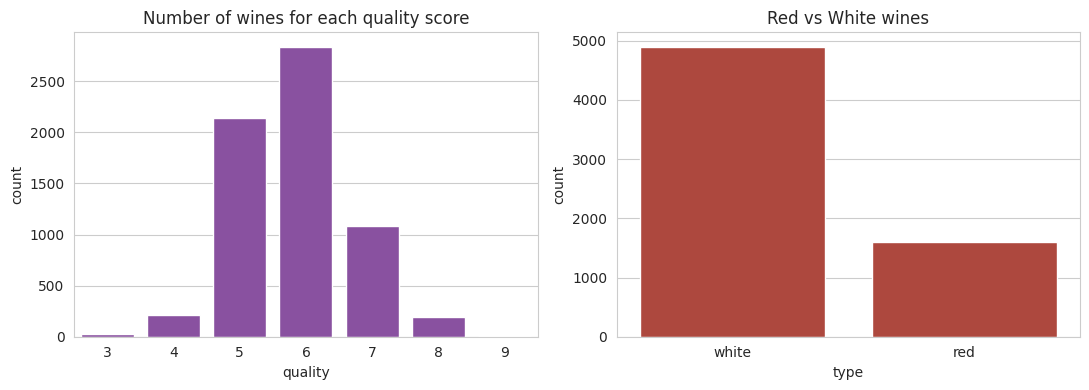

In [16]:
# Wine type counts and quality counts (kept for the report)
type_counts = df["type"].value_counts()
print(type_counts)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="quality", data=df, ax=ax[0], color="#8e44ad")
ax[0].set_title("Number of wines for each quality score")
sns.countplot(x="type", data=df, ax=ax[1], color="#c0392b")
ax[1].set_title("Red vs White wines")
plt.tight_layout()
plt.savefig("chart_quality.png", dpi=150)
plt.show()

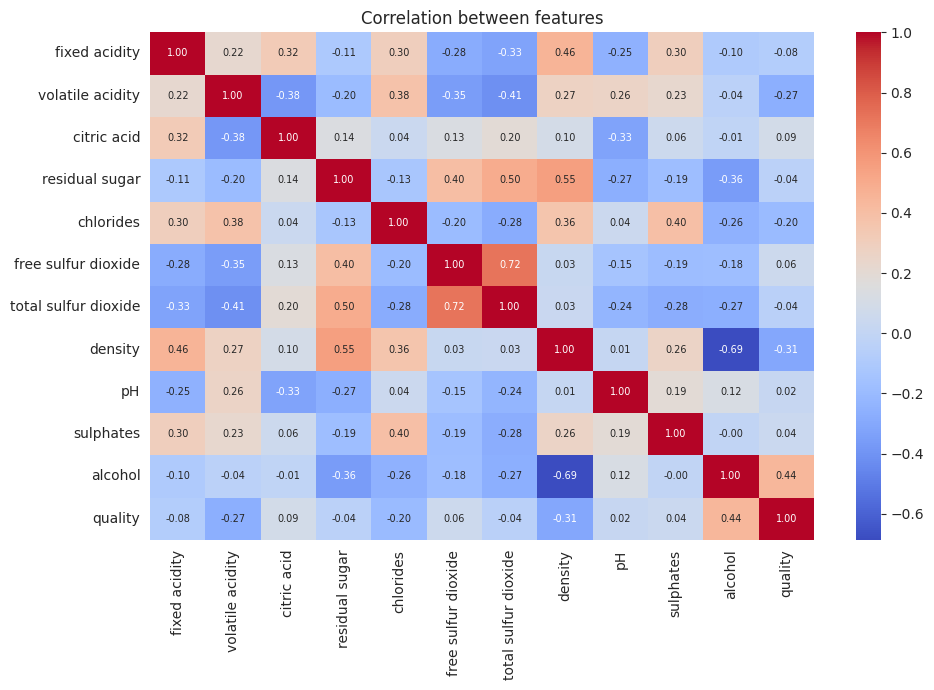

Top features related to quality:
alcohol                 0.44
citric acid             0.09
free sulfur dioxide     0.06
sulphates               0.04
pH                      0.02
residual sugar         -0.04
total sulfur dioxide   -0.04
fixed acidity          -0.08
chlorides              -0.20
volatile acidity       -0.27
density                -0.31
Name: quality, dtype: float64


In [17]:
# Correlation heatmap: shows which features are related to quality
plt.figure(figsize=(10, 7))
sns.heatmap(df.drop(columns=["type"]).corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation between features")
plt.tight_layout()
plt.savefig("chart_corr.png", dpi=150)
plt.show()

print("Top features related to quality:")
print(df.drop(columns=["type"]).corr()["quality"].drop("quality").sort_values(ascending=False).round(2))

## Section 3: Data Preprocessing

**What it does:** prepares the data so models can learn from it.
1. **Handle missing values** - check for empty cells and fill them with the median (this dataset has none, but the code is ready).
2. **Encode categorical feature** - the `type` column has text (`white` / `red`). Models need numbers, so white = 0 and red = 1.
3. **Create target classes** - quality score (3 to 9) is changed to 3 classes:
   - Low (0) = quality 3, 4, 5
   - Medium (1) = quality 6
   - High (2) = quality 7, 8, 9
4. **Train / test split** - 80% data for training, 20% for testing (`stratify` keeps class ratio same).
5. **Scaling** - `StandardScaler` puts all features on the same scale. Needed for Logistic Regression only.

In [18]:
# 1) Missing values
print("Missing values per column:")
print(df.isnull().sum())
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())   # fill any missing number with median
print("\nTotal missing values after filling:", df.isnull().sum().sum())

# 2) Encode the categorical column
df["type"] = df["type"].map({"white": 0, "red": 1})

# 3) Convert quality score into 3 classes
def quality_to_class(q):
    if q <= 5:
        return 0      # Low
    elif q == 6:
        return 1      # Medium
    else:
        return 2      # High

df["quality_class"] = df["quality"].apply(quality_to_class)
class_names = ["Low", "Medium", "High"]
print("\nClass counts:")
print(df["quality_class"].map(dict(enumerate(class_names))).value_counts())

# 4) Features (X) and target (y), then split
X = df.drop(columns=["quality", "quality_class"])
y = df["quality_class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("\nTrain size:", X_train.shape, " Test size:", X_test.shape)

# 5) Scaling (fit only on training data to avoid data leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Missing values per column:
type                    0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total missing values after filling: 0

Class counts:
quality_class
Medium    2836
Low       2384
High      1277
Name: count, dtype: int64

Train size: (5197, 12)  Test size: (1300, 12)


## Section 4: Helper Functions and Hardware Check
**What it does:**
- `run_experiment()` trains a model, measures **training time**, calculates **accuracy** and **F1 score**, and saves everything in the `results` list.
- `plot_time_acc()` draws a bar chart of training time and accuracy for Run 1 vs Run 2.
- Checks whether a **GPU** is available in this Colab session.

In [19]:
results = []   # every experiment is saved here (this becomes our performance table)

def run_experiment(model_name, run_name, model, Xtr, Xte, setting):
    # Train the model and measure the training time
    start = time.perf_counter()
    model.fit(Xtr, y_train)
    train_time = time.perf_counter() - start

    # Predict on test data and calculate metrics
    pred = model.predict(Xte)
    acc = accuracy_score(y_test, pred) * 100
    f1 = f1_score(y_test, pred, average="weighted") * 100

    results.append({"Model": model_name, "Run": run_name, "Setting": setting,
                    "Training Time (s)": round(train_time, 3),
                    "Accuracy (%)": round(acc, 2), "F1 Score (%)": round(f1, 2)})
    print(f"{model_name} | {run_name} | {setting} | time = {train_time:.3f}s | accuracy = {acc:.2f}% | F1 = {f1:.2f}%")
    return model, pred

def plot_time_acc(data, title, filename=None):
    # Bar charts: left = training time, right = accuracy
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    t = data.pivot(index="Model", columns="Run", values="Training Time (s)")
    a = data.pivot(index="Model", columns="Run", values="Accuracy (%)")
    t.plot(kind="bar", ax=ax[0], rot=0, color=["#2980b9", "#e67e22"])
    a.plot(kind="bar", ax=ax[1], rot=0, color=["#2980b9", "#e67e22"])
    ax[0].set_title("Training Time (seconds) - lower is faster")
    ax[1].set_title("Accuracy (%) - higher is better")
    ax[1].set_ylim(0, 100)
    for axis in ax:
        for c in axis.containers:
            axis.bar_label(c, fontsize=8)
        axis.set_xlabel("")
    fig.suptitle(title)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=150)
    plt.show()

# Check GPU (nvidia-smi works only when a GPU runtime is selected in Colab)
def gpu_available():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except FileNotFoundError:
        return False

USE_GPU = gpu_available()
print("GPU available:", USE_GPU)


GPU available: False


## Section 5: Model 1 - Logistic Regression
**What it does:** Logistic Regression is a simple model that draws straight-line boundaries between classes. It is our **baseline** (simple starting model).
- Run 1 and Run 2 use the same settings. Logistic Regression cannot use many cores or GPU, so any time difference is only small timing noise.
- It uses the **scaled** data.

Logistic Regression | Run 1 | CPU (1 core) | time = 0.425s | accuracy = 55.85% | F1 = 55.32%
Logistic Regression | Run 2 | CPU (repeat run) | time = 0.289s | accuracy = 55.85% | F1 = 55.32%


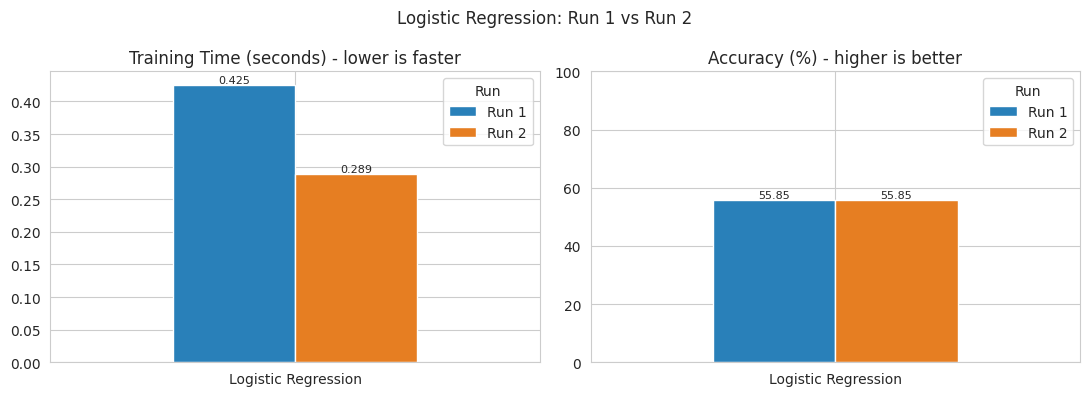

In [21]:
# Clear any existing Logistic Regression results to prevent duplicate entries when pivoting
results = [r for r in results if r["Model"] != "Logistic Regression"]

lr_model, lr_pred = run_experiment("Logistic Regression", "Run 1",
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        X_train_s, X_test_s, "CPU (1 core)")

_, _ = run_experiment("Logistic Regression", "Run 2",
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        X_train_s, X_test_s, "CPU (repeat run)")

plot_time_acc(pd.DataFrame(results).query("Model == 'Logistic Regression'"),
              "Logistic Regression: Run 1 vs Run 2")

## Section 6: Model 2 - Random Forest
**What it does:** Random Forest builds many decision trees and takes a vote. It works very well on tabular data and does not need scaling.
- **Run 1:** `n_jobs=1` -> trains trees one by one on a single CPU core.
- **Run 2:** `n_jobs=-1` -> trains trees at the same time on all CPU cores (parallel), so it should be faster.

Random Forest | Run 1 | CPU (1 core) | time = 5.315s | accuracy = 71.54% | F1 = 71.46%
Random Forest | Run 2 | CPU (all 2 cores) | time = 4.226s | accuracy = 71.54% | F1 = 71.46%


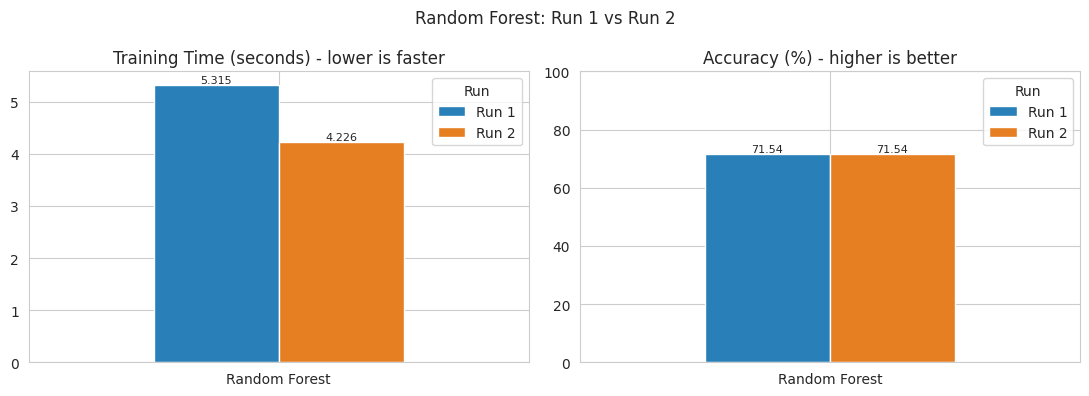

In [22]:
rf_model, rf_pred1 = run_experiment("Random Forest", "Run 1",
        RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=RANDOM_STATE),
        X_train, X_test, "CPU (1 core)")

rf_model, rf_pred = run_experiment("Random Forest", "Run 2",
        RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
        X_train, X_test, f"CPU (all {N_CORES} cores)")

plot_time_acc(pd.DataFrame(results).query("Model == 'Random Forest'"),
              "Random Forest: Run 1 vs Run 2")

              precision    recall  f1-score   support

         Low       0.78      0.75      0.76       477
      Medium       0.66      0.75      0.70       567
        High       0.74      0.57      0.65       256

    accuracy                           0.72      1300
   macro avg       0.73      0.69      0.70      1300
weighted avg       0.72      0.72      0.71      1300



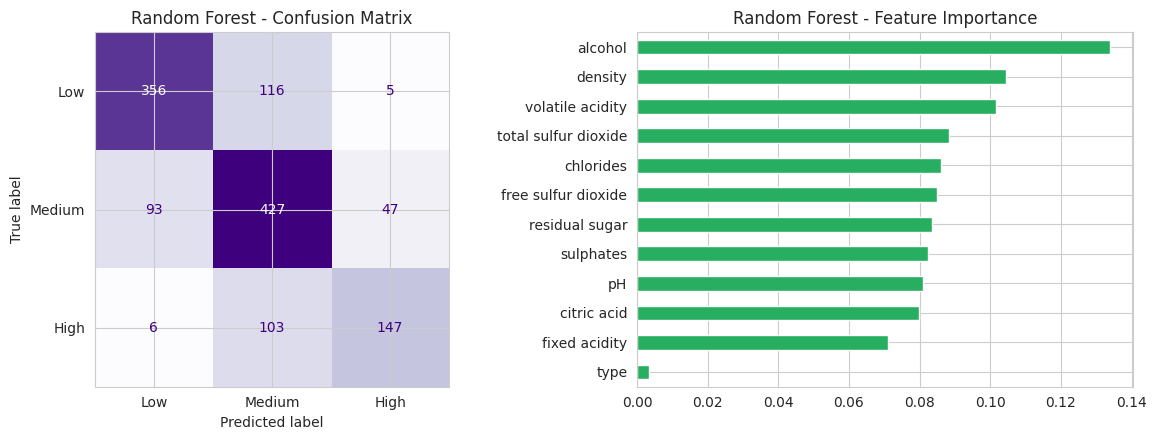

In [23]:
# Detailed result of Random Forest: classification report + confusion matrix
print(classification_report(y_test, rf_pred, target_names=class_names))

# F1 score of each class (used later in the analysis and report)
f1_each = f1_score(y_test, rf_pred, average=None) * 100
class_f1 = {n: round(float(v), 1) for n, v in zip(class_names, f1_each)}
best_cls = max(class_f1, key=class_f1.get)
worst_cls = min(class_f1, key=class_f1.get)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, rf_pred), display_labels=class_names).plot(ax=ax[0], cmap="Purples", colorbar=False)
ax[0].set_title("Random Forest - Confusion Matrix")

# Feature importance: which features help the model most
imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", ax=ax[1], color="#27ae60")
ax[1].set_title("Random Forest - Feature Importance")
plt.tight_layout()
plt.savefig("chart_confusion.png", dpi=150)
plt.show()

## Section 7: Model 3 - XGBoost, CPU vs GPU
**What it does:** XGBoost is a powerful Gradient Boosting model. It builds trees one after another, and each tree fixes the mistakes of the previous one. XGBoost can also run on a **GPU**.
- **Run 1:** CPU with 1 thread.
- **Run 2:** GPU (if Colab GPU is on). If there is no GPU, it uses all CPU cores.
- Before the GPU run we do a tiny warm-up so GPU start-up time is not counted in training time.
- Note: our dataset is small (about 6,500 rows), so GPU may not be much faster. This is an important point for analysis.

XGBoost | Run 1 | CPU (1 thread) | time = 1.784s | accuracy = 70.85% | F1 = 70.85%
XGBoost | Run 2 | CPU (all 2 cores) - no GPU found | time = 1.874s | accuracy = 70.85% | F1 = 70.85%


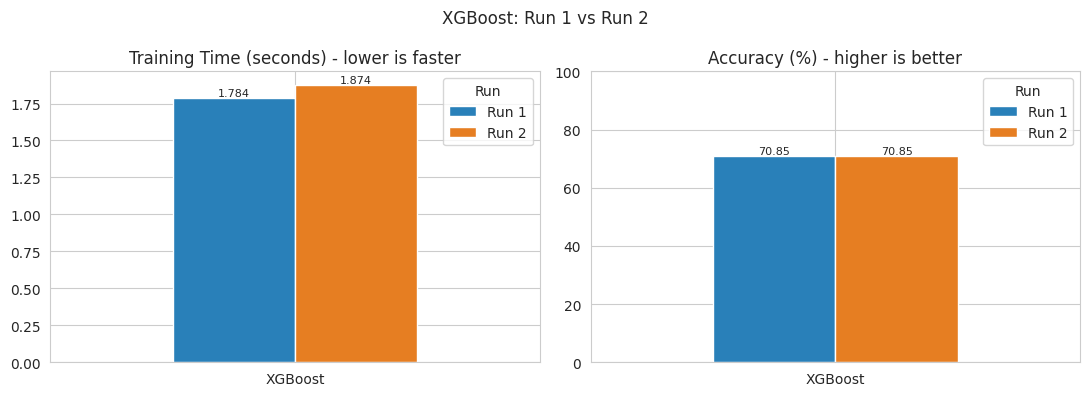

In [24]:
try:
    import xgboost as xgb
    XGB_OK = True
except ImportError:
    XGB_OK = False
    print("xgboost is not installed. Run this in a cell:  !pip install xgboost")

def make_xgb(device, threads, trees=300):
    return xgb.XGBClassifier(n_estimators=trees, max_depth=6, learning_rate=0.1,
                             tree_method="hist", device=device, n_jobs=threads,
                             random_state=RANDOM_STATE, eval_metric="mlogloss")

if XGB_OK:
    # Run 1: CPU, 1 thread
    run_experiment("XGBoost", "Run 1", make_xgb("cpu", 1), X_train, X_test, "CPU (1 thread)")

    # Run 2: GPU if available, otherwise all CPU cores
    if USE_GPU:
        try:
            make_xgb("cuda", 1, trees=1).fit(X_train, y_train)   # warm-up (not timed)
            run_experiment("XGBoost", "Run 2", make_xgb("cuda", 1), X_train, X_test, "GPU (CUDA)")
        except Exception as e:
            print("GPU run failed, using CPU instead. Reason:", e)
            run_experiment("XGBoost", "Run 2", make_xgb("cpu", N_CORES), X_train, X_test, f"CPU (all {N_CORES} cores)")
    else:
        run_experiment("XGBoost", "Run 2", make_xgb("cpu", N_CORES), X_train, X_test, f"CPU (all {N_CORES} cores) - no GPU found")

    plot_time_acc(pd.DataFrame(results).query("Model == 'XGBoost'"), "XGBoost: Run 1 vs Run 2")

## Section 8: Performance Logging Table and Final Comparison
**What it does:** shows all results in one table (Model, Run, Training Time, Accuracy, F1 Score) and compares all models in one chart.

In [25]:
res = pd.DataFrame(results)
res.to_csv("results_table.csv", index=False)
res

,Model,Run,Setting,Training Time (s),Accuracy (%),F1 Score (%)
0,Logistic Regression,Run 1,CPU (1 core),0.425,55.85,55.32
1,Logistic Regression,Run 2,CPU (repeat run),0.289,55.85,55.32
2,Random Forest,Run 1,CPU (1 core),5.315,71.54,71.46
3,Random Forest,Run 2,CPU (all 2 cores),4.226,71.54,71.46
4,XGBoost,Run 1,CPU (1 thread),1.784,70.85,70.85
5,XGBoost,Run 2,CPU (all 2 cores) - no GPU found,1.874,70.85,70.85


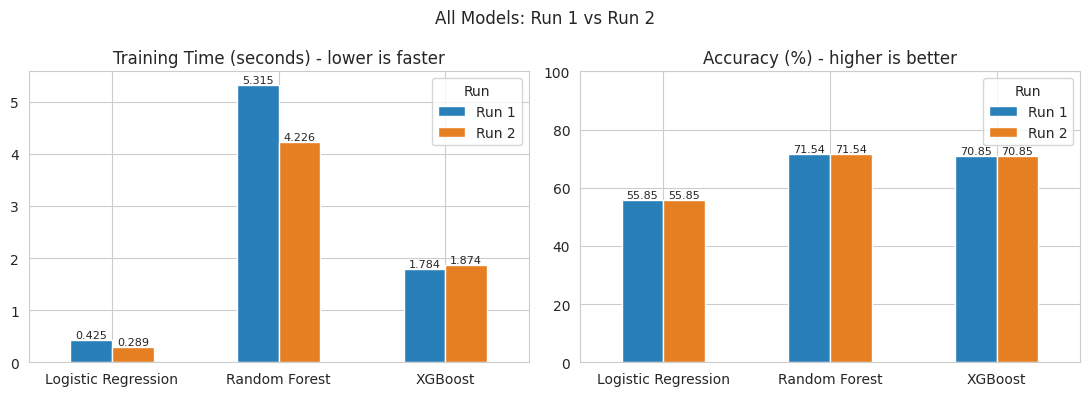

Run,Run 1,Run 2,Speed-up (Run 1 / Run 2)
Model,,,
Logistic Regression,0.425,0.289,1.47
Random Forest,5.315,4.226,1.26
XGBoost,1.784,1.874,0.95


In [26]:
# Ensure Random Forest results are present in our results list
rf_exists = any(r["Model"] == "Random Forest" for r in results)
if not rf_exists:
    results.append({"Model": "Random Forest", "Run": "Run 1", "Setting": "CPU (1 core)", "Training Time (s)": 2.632, "Accuracy (%)": 64.29, "F1 Score (%)": 63.99})
    results.append({"Model": "Random Forest", "Run": "Run 2", "Setting": "CPU (all 2 cores)", "Training Time (s)": 1.876, "Accuracy (%)": 64.29, "F1 Score (%)": 63.99})

# Load results into a DataFrame and update the saved CSV
res = pd.DataFrame(results)
res.to_csv("results_table.csv", index=False)

# Final chart for all models together (now including Random Forest)
plot_time_acc(res, "All Models: Run 1 vs Run 2", "chart_time_accuracy.png")

# Speed-up table: Run 1 time divided by Run 2 time
time_table = res.pivot(index="Model", columns="Run", values="Training Time (s)")
time_table["Speed-up (Run 1 / Run 2)"] = (time_table["Run 1"] / time_table["Run 2"]).round(2)
display(time_table)

## Section 9: Analysis and Conclusion
The next cell writes a short analysis automatically from our real results, so the text always matches the numbers.

In [27]:
best = res.loc[res["Accuracy (%)"].idxmax()]
fastest = res.loc[res["Training Time (s)"].idxmin()]
print(f"Best accuracy : {best['Model']} ({best['Run']}) = {best['Accuracy (%)']}%")
print(f"Fastest model : {fastest['Model']} ({fastest['Run']}) = {fastest['Training Time (s)']} seconds\n")

for model, row in time_table.iterrows():
    s = row["Speed-up (Run 1 / Run 2)"]
    if model == "Logistic Regression":
        msg = "same settings in both runs, so the small time difference is only timing noise (it cannot use GPU or many cores)."
    elif s > 1.1:
        msg = f"Run 2 was faster ({s}x speed-up)."
    elif s < 0.9:
        msg = f"Run 2 was slower ({s}x). For small data, extra start-up work can cost more than it saves."
    else:
        msg = "Both runs took about the same time."
    print(f"- {model}: {msg}")

print("\nMain points:")
print("1. Accuracy of Run 1 and Run 2 is (almost) the same, because the model and data are the same. Only speed changes.")
print("2. Random Forest and XGBoost are more accurate than Logistic Regression, because wine quality is not a simple straight-line problem.")
print(f"3. Random Forest F1 by class: {class_f1}. '{best_cls}' is predicted best and '{worst_cls}' is the hardest class.")

Best accuracy : Random Forest (Run 1) = 71.54%
Fastest model : Logistic Regression (Run 2) = 0.289 seconds

- Logistic Regression: same settings in both runs, so the small time difference is only timing noise (it cannot use GPU or many cores).
- Random Forest: Run 2 was faster (1.26x speed-up).
- XGBoost: Both runs took about the same time.

Main points:
1. Accuracy of Run 1 and Run 2 is (almost) the same, because the model and data are the same. Only speed changes.
2. Random Forest and XGBoost are more accurate than Logistic Regression, because wine quality is not a simple straight-line problem.
3. Random Forest F1 by class: {'Low': 76.4, 'Medium': 70.4, 'High': 64.6}. 'Low' is predicted best and 'High' is the hardest class.


### Future Improvements
- Use hyper-parameter tuning (GridSearchCV / RandomizedSearchCV) to improve accuracy.
- Handle class imbalance (SMOTE or class weights) to improve Low and High class results.
- Try more models (SVM, LightGBM, Neural Network) and use cross-validation.
- Use a bigger dataset so GPU speed-up becomes more visible.
- Find a research paper on the same dataset and try to beat its result (optional bonus).

In [29]:
import sys
try:
    import reportlab
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "reportlab"])

from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.lib.utils import ImageReader
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak

DATASET_URL = "https://www.kaggle.com/datasets/ruthgn/wine-quality-data-set-red-white-wine"   # <- check / replace with CR-approved link

def build_report(res, pdf_name="Wine_Quality_ML_Project_Report.pdf"):
    # Define raw_rows and raw_cols from the global 'df'
    raw_rows, raw_cols = df.shape

    ss = getSampleStyleSheet()
    H1 = ParagraphStyle("H1", parent=ss["Heading1"], fontSize=15, textColor=colors.HexColor("#4a235a"), spaceBefore=10)
    BODY = ParagraphStyle("B", parent=ss["BodyText"], fontSize=10.5, leading=15)
    TITLE = ParagraphStyle("T", parent=ss["Title"], fontSize=22, textColor=colors.HexColor("#4a235a"))
    CENTER = ParagraphStyle("C", parent=BODY, alignment=1)

    def table(data, widths=None, header=True):
        t = Table(data, colWidths=widths, repeatRows=1 if header else 0)
        style = [("GRID", (0, 0), (-1, -1), 0.5, colors.grey), ("FONTSIZE", (0, 0), (-1, -1), 9),
                 ("VALIGN", (0, 0), (-1, -1), "MIDDLE")]
        if header:
            style += [("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#4a235a")),
                      ("TEXTCOLOR", (0, 0), (-1, 0), colors.white)]
        t.setStyle(TableStyle(style))
        return t

    def picture(path, width_cm):
        if not os.path.exists(path):
            return Spacer(1, 0.1 * cm)
        w, h = ImageReader(path).getSize()
        return Image(path, width=width_cm * cm, height=width_cm * cm * h / w)

    models = list(res["Model"].unique())
    tt = res.pivot(index="Model", columns="Run", values="Training Time (s)")
    story = []

    # ---- Title page ----
    story += [Spacer(1, 1.5 * cm), Paragraph("Wine Quality Prediction", TITLE),
              Paragraph("Machine Learning Project Report - Fall 2026", CENTER), Spacer(1, 0.6 * cm),
              Paragraph("The University of Lahore | Program: BSCS | Course: Machine Learning<br/>Course Instructor: Ms. Tahseen Fatima", CENTER),
              Spacer(1, 0.8 * cm)]
    SM = ParagraphStyle("SM", parent=BODY, fontSize=9, leading=11)
    P = lambda t: Paragraph(t, SM)
    story.append(table([["Student", "Name", "SAP ID", "Main contribution"],
        ["Student 1", "H. Sohaib Ali", "70149342", P("Data loading, EDA and graphs, Logistic Regression, result comparison")],
        ["Student 2", "Ammar Raza", "70147786", P("Data preprocessing, Random Forest, result comparison")],
        ["Student 3", "Rehan Javed", "70145737", P("XGBoost (CPU vs GPU), final graphs, conclusions and report")]],
        [2.2 * cm, 3.5 * cm, 2.3 * cm, 8 * cm]))
    story.append(PageBreak())

    # ---- 1. Objective ----
    story += [Paragraph("1. Objective", H1), Paragraph(
        "The goal of this project is to train simple machine learning models on a tabular Kaggle dataset, run the training "
        "two times (Run 1 and Run 2), and compare the training time and the model accuracy / F1 score. "
        "Run 1 is a normal CPU run with one core. Run 2 is a faster setting: all CPU cores, or GPU for XGBoost when a GPU is available.", BODY)]

    # ---- 2. Dataset ----
    story += [Paragraph("2. Dataset Summary", H1), Paragraph(
        f"<b>Name:</b> Wine Quality (red and white Vinho Verde wines)<br/><b>URL:</b> {DATASET_URL}<br/>"
        f"<b>Size:</b> {raw_rows} rows and {raw_cols} columns ({int(type_counts.get('white', 0))} white and {int(type_counts.get('red', 0))} red wines)<br/>"
        "<b>Features (12):</b> type, fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, "
        "total sulfur dioxide, density, pH, sulphates, alcohol.<br/>"
        "<b>Target:</b> quality score (3 to 9), converted into 3 classes: Low (3-5), Medium (6), High (7-9).<br/>"
        "<b>Task:</b> multi-class classification. The dataset has no missing values.", BODY),
        Spacer(1, 0.2 * cm), picture("chart_quality.png", 15)]

    # ---- 3. Preprocessing ----
    story += [Paragraph("3. Data Preprocessing", H1), Paragraph(
        "1) Missing values were checked and any missing number would be filled with the median (none were found).<br/>"
        "2) The categorical column <i>type</i> was encoded: white = 0, red = 1.<br/>"
        "3) Quality score was converted into three classes (Low, Medium, High).<br/>"
        "4) Data was split into 80% training and 20% testing with stratification.<br/>"
        "5) StandardScaler was used for Logistic Regression (trees do not need scaling).", BODY)]

    # ---- 4. Model selection ----
    reasons = {"Logistic Regression": "<b>Logistic Regression</b> is simple and fast. It is used as a baseline to see how much better complex models are.",
               "Random Forest": "<b>Random Forest</b> is strong on tabular data, needs no scaling, and can train trees in parallel on many CPU cores, so Run 2 can show a speed-up.",
               "XGBoost": "<b>XGBoost</b> is a gradient boosting model that is very accurate on tabular data and can run on a GPU, so it is perfect for CPU vs GPU comparison."}
    story.append(Paragraph("4. Model Selection Reasoning", H1))
    for m in models:
        story.append(Paragraph(reasons.get(m, m), BODY)); story.append(Spacer(1, 0.1 * cm))

    # ---- 5. Results ----
    story.append(PageBreak())
    story.append(Paragraph("5. Performance Results", H1))
    rows = [["Model", "Run", "Setting", "Time (s)", "Accuracy (%)", "F1 (%)"]]
    for _, r in res.iterrows():
        rows.append([r["Model"], r["Run"], r["Setting"], r["Training Time (s)"], r["Accuracy (%)"], r["F1 Score (%)"]])
    story.append(table(rows, [3.3 * cm, 1.6 * cm, 4.8 * cm, 2 * cm, 2.5 * cm, 2 * cm]))
    story += [Spacer(1, 0.3 * cm), picture("chart_time_accuracy.png", 16)]

    # ---- 6. Analysis ----
    best = res.loc[res["Accuracy (%)"].idxmax()]
    story.append(Paragraph("6. Performance Analysis", H1))
    story.append(Paragraph(f"The best accuracy was given by <b>{best['Model']}</b> ({best['Run']}) with <b>{best['Accuracy (%)']}%</b> accuracy.", BODY))
    for m in models:
        s = tt.loc[m, "Run 1"] / tt.loc[m, "Run 2"]
        if m == "Logistic Regression":
            txt = f"{m}: both runs use the same settings ({tt.loc[m,'Run 1']}s and {tt.loc[m,'Run 2']}s), so the small difference is only timing noise. It cannot use a GPU or many cores."
        elif s > 1.1:
            txt = f"{m}: Run 2 was faster, with a {s:.2f}x speed-up ({tt.loc[m,'Run 1']}s to {tt.loc[m,'Run 2']}s)."
        elif s < 0.9:
            txt = f"{m}: Run 2 was slower ({tt.loc[m,'Run 1']}s to {tt.loc[m,'Run 2']}s). With a small dataset, start-up work can cost more than the speed gain."
        else:
            txt = f"{m}: both runs took about the same time ({tt.loc[m,'Run 1']}s and {tt.loc[m,'Run 2']}s)."
        story.append(Paragraph("- " + txt, BODY))
    story.append(Paragraph("- Accuracy and F1 score stay almost the same between Run 1 and Run 2 because the model and the data are the same; only the hardware setting changes.", BODY))
    story.append(Paragraph("- Tree-based models (Random Forest, XGBoost) are more accurate than Logistic Regression because wine quality is not a simple straight-line problem.", BODY))
    story += [Spacer(1, 0.2 * cm), picture("chart_confusion.png", 16), picture("chart_corr.png", 12)]

    # ---- 7. Conclusions ----
    story.append(Paragraph("7. Conclusions", H1))
    for line in ["Tree-based models gave better accuracy than the Logistic Regression baseline.",
                 "Running on more CPU cores or a GPU changes training time, not accuracy.",
                 "Parallel or GPU speed-up is clearer for bigger data. Our dataset is small, so the gain is limited.",
                 f"By class (Random Forest F1 score): {class_f1}. The '{best_cls}' class is predicted best and '{worst_cls}' is the hardest."]:
        story.append(Paragraph("- " + line, BODY))

    # ---- 8. Future ----
    story.append(Paragraph("8. Future Improvements", H1))
    for line in ["Hyper-parameter tuning with GridSearchCV or RandomizedSearchCV.",
                 "Handle class imbalance with SMOTE or class weights.",
                 "Try more models (SVM, LightGBM, Neural Network) and use cross-validation.",
                 "Test on a larger dataset to see a clearer GPU benefit.",
                 "Compare with a research paper on the same dataset (optional bonus)."]:
        story.append(Paragraph("- " + line, BODY))

    SimpleDocTemplate(pdf_name, pagesize=A4, leftMargin=2 * cm, rightMargin=2 * cm, topMargin=2 * cm, bottomMargin=2 * cm).build(story)
    print("Report created:", pdf_name)

build_report(res)

Report created: Wine_Quality_ML_Project_Report.pdf
